In [ ]:
from google.colab import drive
drive.mount('/content/drive')

import os, numpy as np, tensorflow as tf, keras
from keras import layers

PROJ = '/content/drive/MyDrive/DATAX504_final'
for d in ['data', 'checkpoints', 'logs', 'models']:
    os.makedirs(f'{PROJ}/{d}', exist_ok=True)

print("GPU:", tf.config.list_physical_devices('GPU'))

Mounted at /content/drive
GPU: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


In [ ]:
import os, json, subprocess, pathlib
import numpy as np
import pandas as pd
from sklearn.model_selection import StratifiedGroupKFold

# --- 1. Dataset (colour images only)
DATA_DIR = '/content/plantvillage'
if not os.path.isdir(f'{DATA_DIR}/raw/color'):
    print("Downloading PlantVillage (takes a few minutes)...")
    subprocess.run(['git', 'clone', '--depth', '1', '--filter=blob:none', '--sparse',
                    'https://github.com/spMohanty/PlantVillage-Dataset.git', DATA_DIR], check=True)
    subprocess.run(['git', '-C', DATA_DIR, 'sparse-checkout', 'set', 'raw/color'], check=True)
print("Dataset ready")

# --- 2. Leaf map: which photos show the same physical leaf ---
leaf_map = json.loads(subprocess.run(['git', '-C', DATA_DIR, 'show', 'HEAD:leaf-map.json'],
                                     capture_output=True, text=True, check=True).stdout)

# --- 3. File paths, labels, leaf groups ---
ROOT = pathlib.Path(DATA_DIR) / 'raw' / 'color'
class_names = sorted(p.name for p in ROOT.iterdir() if p.is_dir())
paths, labels, groups = [], [], []
for i, c in enumerate(class_names):
    for f in sorted((ROOT / c).iterdir()):
        if f.suffix.lower() in ('.jpg', '.jpeg', '.png'):
            key = f.stem.split('___')[-1].lower().strip()      # drop the UUID prefix
            paths.append(str(f)); labels.append(i)
            groups.append(leaf_map[key][0] if key in leaf_map else f'single:{len(paths)}')
paths, labels, groups = np.array(paths), np.array(labels), np.array(groups)
mapped = np.array([not g.startswith('single:') for g in groups])
print("Classes:", len(class_names), "| Images:", len(paths))
print(f"Known leaf id: {mapped.sum()} ({mapped.mean():.1%}) | distinct leaves: {len(set(groups[mapped]))}")

# --- 4. Stratified, leaf-grouped 70/15/15 split ---
sgkf = StratifiedGroupKFold(n_splits=20, shuffle=True, random_state=42)
fold = np.full(len(paths), -1)
for k, (_, idx) in enumerate(sgkf.split(paths, labels, groups)):
    fold[idx] = k
split = np.where(fold < 14, 'train', np.where(fold < 17, 'val', 'test'))

p_train, y_train = paths[split == 'train'], labels[split == 'train']
p_val,   y_val   = paths[split == 'val'],   labels[split == 'val']
p_test,  y_test  = paths[split == 'test'],  labels[split == 'test']
print("Train/Val/Test:", len(p_train), len(p_val), len(p_test))

spans = pd.Series(split[mapped]).groupby(groups[mapped]).nunique()
print("Leaves appearing in more than one split:", int((spans > 1).sum()))

pd.DataFrame({'path': paths, 'label': labels, 'class': np.array(class_names)[labels],
              'group': groups, 'split': split}).to_csv(f'{PROJ}/logs/split.csv', index=False)
json.dump(class_names, open(f'{PROJ}/class_names.json', 'w'))

# --- 5. tf.data pipelines ---
IMG, BATCH = 160, 64
AUTOTUNE = tf.data.AUTOTUNE

def load(path, label):
    img = tf.io.decode_image(tf.io.read_file(path), channels=3, expand_animations=False)
    img.set_shape([None, None, 3])
    return tf.image.resize(img, (IMG, IMG)), label

def make_ds(p, y, training=False):
    ds = tf.data.Dataset.from_tensor_slices((p, y))
    if training:
        ds = ds.shuffle(len(p), seed=42)
    return ds.map(load, AUTOTUNE).batch(BATCH).prefetch(AUTOTUNE)

train_ds = make_ds(p_train, y_train, training=True)
val_ds   = make_ds(p_val, y_val)
test_ds  = make_ds(p_test, y_test)
x, y = next(iter(train_ds))
print("Batch:", x.shape, y.shape)

Dataset ready
Classes: 38 | Images: 54305
Known leaf id: 41111 (75.7%) | distinct leaves: 7286
Train/Val/Test: 38094 7991 8220
Leaves appearing in more than one split: 0
Batch: (64, 160, 160, 3) (64,)


In [ ]:
# --- Rebuild pipelines: uint8 + cached in memory (much faster after epoch 1) ---
def load_u8(path, label):
    img = tf.io.decode_image(tf.io.read_file(path), channels=3, expand_animations=False)
    img.set_shape([None, None, 3])
    img = tf.image.resize(img, (IMG, IMG))
    return tf.cast(tf.round(img), tf.uint8), label

def make_ds(p, y, training=False):
    ds = tf.data.Dataset.from_tensor_slices((p, y)).map(load_u8, AUTOTUNE).cache()
    if training:
        ds = ds.shuffle(5000, seed=42)
    return ds.batch(BATCH).prefetch(AUTOTUNE)

train_ds = make_ds(p_train, y_train, training=True)
val_ds   = make_ds(p_val, y_val)
test_ds  = make_ds(p_test, y_test)

# --- Baseline CNN from scratch (3 conv blocks) ---
def build_baseline():
    inp = keras.Input((IMG, IMG, 3))
    x = layers.Rescaling(1/255)(inp)
    for f in (32, 64, 128):
        x = layers.Conv2D(f, 3, padding='same', activation='relu')(x)
        x = layers.MaxPooling2D()(x)
    x = layers.GlobalAveragePooling2D()(x)
    x = layers.Dropout(0.3)(x)
    out = layers.Dense(len(class_names), activation='softmax')(x)
    return keras.Model(inp, out, name='baseline_cnn')

baseline = build_baseline()
baseline.compile(optimizer=keras.optimizers.Adam(1e-3),
                 loss='sparse_categorical_crossentropy',
                 metrics=['accuracy'])
baseline.summary()

callbacks = [
    keras.callbacks.BackupAndRestore(backup_dir=f'{PROJ}/checkpoints/baseline'),
    keras.callbacks.ModelCheckpoint(f'{PROJ}/models/baseline_best.keras',
                                    monitor='val_loss', save_best_only=True),
    keras.callbacks.CSVLogger(f'{PROJ}/logs/baseline_log.csv', append=True),
    keras.callbacks.EarlyStopping(monitor='val_loss', patience=3, restore_best_weights=True),
]

history = baseline.fit(train_ds, validation_data=val_ds,
                       epochs=12, callbacks=callbacks, verbose=2)

# --- Validation result (test set stays untouched until the end) ---
val_loss, val_acc = baseline.evaluate(val_ds, verbose=0)
print(f"Baseline validation accuracy: {val_acc:.4f}")

results_path = f'{PROJ}/logs/results.json'
results = json.load(open(results_path)) if os.path.exists(results_path) else {}
results['baseline_val_acc'] = float(val_acc)
json.dump(results, open(results_path, 'w'))

Model: "baseline_cnn"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer (InputLayer)        │ (None, 160, 160, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ rescaling (Rescaling)           │ (None, 160, 160, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 160, 160, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 80, 80, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 80, 80, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 40, 40, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 40, 40, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 20, 20, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 128)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 38)             │         4,902 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 98,150 (383.40 KB)

 Trainable params: 98,150 (383.40 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/12
596/596 - 65s - 109ms/step - accuracy: 0.3512 - loss: 2.4251 - val_accuracy: 0.1337 - val_loss: 4.3445
Epoch 2/12
596/596 - 51s - 86ms/step - accuracy: 0.4655 - loss: 1.8398 - val_accuracy: 0.2423 - val_loss: 3.7421
Epoch 3/12
596/596 - 34s - 58ms/step - accuracy: 0.5909 - loss: 1.3776 - val_accuracy: 0.3135 - val_loss: 3.1089
Epoch 4/12
596/596 - 34s - 56ms/step - accuracy: 0.6517 - loss: 1.1593 - val_accuracy: 0.3644 - val_loss: 2.6650
Epoch 5/12
596/596 - 34s - 57ms/step - accuracy: 0.6968 - loss: 1.0060 - val_accuracy: 0.3806 - val_loss: 2.5179
Epoch 6/12
596/596 - 34s - 57ms/step - accuracy: 0.7262 - loss: 0.8939 - val_accuracy: 0.4340 - val_loss: 2.3194
Epoch 7/12
596/596 - 34s - 57ms/step - accuracy: 0.7472 - loss: 0.8228 - val_accuracy: 0.4713 - val_loss: 2.2555
Epoch 8/12
596/596 - 34s - 57ms/step - accuracy: 0.7660 - loss: 0.7531 - val_accuracy: 0.4675 - val_loss: 2.0515
Epoch 9/12
596/596 - 34s - 57ms/step - accuracy: 0.7839 - loss: 0.7002 - val_accuracy: 0.5042 -

In [ ]:
# --- MobileNetV2 (ImageNet weights), base frozen, new head ---
def build_frozen():
    base = keras.applications.MobileNetV2(
        input_shape=(IMG, IMG, 3), include_top=False, weights='imagenet')
    base.trainable = False

    inp = keras.Input((IMG, IMG, 3))
    x = layers.RandomFlip('horizontal_and_vertical')(inp)   # augmentation (training only)
    x = layers.RandomRotation(0.1)(x)
    x = layers.RandomZoom(0.1)(x)
    x = layers.Rescaling(1/127.5, offset=-1)(x)             # MobileNetV2 expects [-1, 1]
    x = base(x, training=False)                             # keep BatchNorm in inference mode
    x = layers.GlobalAveragePooling2D()(x)
    x = layers.Dropout(0.3)(x)
    out = layers.Dense(len(class_names), activation='softmax')(x)
    return keras.Model(inp, out, name='mobilenetv2_frozen'), base

model, base = build_frozen()
model.compile(optimizer=keras.optimizers.Adam(1e-3),
              loss='sparse_categorical_crossentropy',
              metrics=['accuracy'])

callbacks = [
    keras.callbacks.BackupAndRestore(backup_dir=f'{PROJ}/checkpoints/frozen'),
    keras.callbacks.ModelCheckpoint(f'{PROJ}/models/mobilenet_frozen_best.keras',
                                    monitor='val_loss', save_best_only=True),
    keras.callbacks.CSVLogger(f'{PROJ}/logs/frozen_log.csv', append=True),
    keras.callbacks.EarlyStopping(monitor='val_loss', patience=2, restore_best_weights=True),
]

history_frozen = model.fit(train_ds, validation_data=val_ds,
                           epochs=6, callbacks=callbacks, verbose=2)

val_loss, val_acc = model.evaluate(val_ds, verbose=0)
print(f"MobileNetV2 (frozen) validation accuracy: {val_acc:.4f}")

results = json.load(open(results_path))
results['frozen_val_acc'] = float(val_acc)
json.dump(results, open(results_path, 'w'))

9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
Epoch 1/6
596/596 - 59s - 98ms/step - accuracy: 0.7652 - loss: 0.8574 - val_accuracy: 0.7531 - val_loss: 0.8004
Epoch 2/6
596/596 - 44s - 74ms/step - accuracy: 0.8917 - loss: 0.3420 - val_accuracy: 0.8294 - val_loss: 0.5332
Epoch 3/6
596/596 - 44s - 74ms/step - accuracy: 0.9145 - loss: 0.2699 - val_accuracy: 0.8546 - val_loss: 0.4525
Epoch 4/6
596/596 - 44s - 73ms/step - accuracy: 0.9215 - loss: 0.2401 - val_accuracy: 0.8651 - val_loss: 0.4113
Epoch 5/6
596/596 - 44s - 73ms/step - accuracy: 0.9287 - loss: 0.2188 - val_accuracy: 0.8672 - val_loss: 0.4078
Epoch 6/6
596/596 - 44s - 73ms/step - accuracy: 0.9324 - loss: 0.2091 - val_accuracy: 0.8785 - val_loss: 0.3941
MobileNetV2 (frozen) validation accuracy: 0.8785


In [ ]:
# --- Start from the best frozen model (also works after a reconnect) ---
if 'model' not in globals():
    model = keras.models.load_model(f'{PROJ}/models/mobilenet_frozen_best.keras')
base = next(l for l in model.layers if isinstance(l, keras.Model))

# --- Unfreeze the top of the base; keep BatchNorm layers frozen ---
base.trainable = True
for layer in base.layers[:100]:
    layer.trainable = False
for layer in base.layers:
    if isinstance(layer, layers.BatchNormalization):
        layer.trainable = False
print("Trainable layers in base:", sum(l.trainable for l in base.layers), "of", len(base.layers))

# --- Recompile with a LOW learning rate (required after changing trainable) ---
model.compile(optimizer=keras.optimizers.Adam(1e-4),
              loss='sparse_categorical_crossentropy',
              metrics=['accuracy'])

callbacks = [
    keras.callbacks.BackupAndRestore(backup_dir=f'{PROJ}/checkpoints/finetune'),
    keras.callbacks.ModelCheckpoint(f'{PROJ}/models/mobilenet_finetuned_best.keras',
                                    monitor='val_loss', save_best_only=True),
    keras.callbacks.CSVLogger(f'{PROJ}/logs/finetune_log.csv', append=True),
    keras.callbacks.EarlyStopping(monitor='val_loss', patience=3, restore_best_weights=True),
]

history_ft = model.fit(train_ds, validation_data=val_ds,
                       epochs=8, callbacks=callbacks, verbose=2)

val_loss, val_acc = model.evaluate(val_ds, verbose=0)
print(f"MobileNetV2 (fine-tuned) validation accuracy: {val_acc:.4f}")

results = json.load(open(results_path))
results['finetuned_val_acc'] = float(val_acc)
json.dump(results, open(results_path, 'w'))

Trainable layers in base: 36 of 154
Epoch 1/8
596/596 - 69s - 115ms/step - accuracy: 0.9228 - loss: 0.2378 - val_accuracy: 0.9233 - val_loss: 0.2474
Epoch 2/8
596/596 - 78s - 131ms/step - accuracy: 0.9520 - loss: 0.1480 - val_accuracy: 0.9150 - val_loss: 0.2720
Epoch 3/8
596/596 - 55s - 93ms/step - accuracy: 0.9628 - loss: 0.1118 - val_accuracy: 0.9384 - val_loss: 0.1964
Epoch 4/8
596/596 - 55s - 93ms/step - accuracy: 0.9664 - loss: 0.1003 - val_accuracy: 0.9227 - val_loss: 0.2297
Epoch 5/8
596/596 - 55s - 92ms/step - accuracy: 0.9724 - loss: 0.0809 - val_accuracy: 0.9398 - val_loss: 0.2140
Epoch 6/8
596/596 - 56s - 94ms/step - accuracy: 0.9738 - loss: 0.0784 - val_accuracy: 0.9522 - val_loss: 0.1531
Epoch 7/8
596/596 - 56s - 94ms/step - accuracy: 0.9757 - loss: 0.0720 - val_accuracy: 0.9493 - val_loss: 0.1482
Epoch 8/8
596/596 - 55s - 93ms/step - accuracy: 0.9792 - loss: 0.0619 - val_accuracy: 0.9366 - val_loss: 0.2028
MobileNetV2 (fine-tuned) validation accuracy: 0.9493


Baseline CNN: test accuracy = 0.5391
MobileNetV2 (frozen): test accuracy = 0.8617
MobileNetV2 (fine-tuned): test accuracy = 0.9455


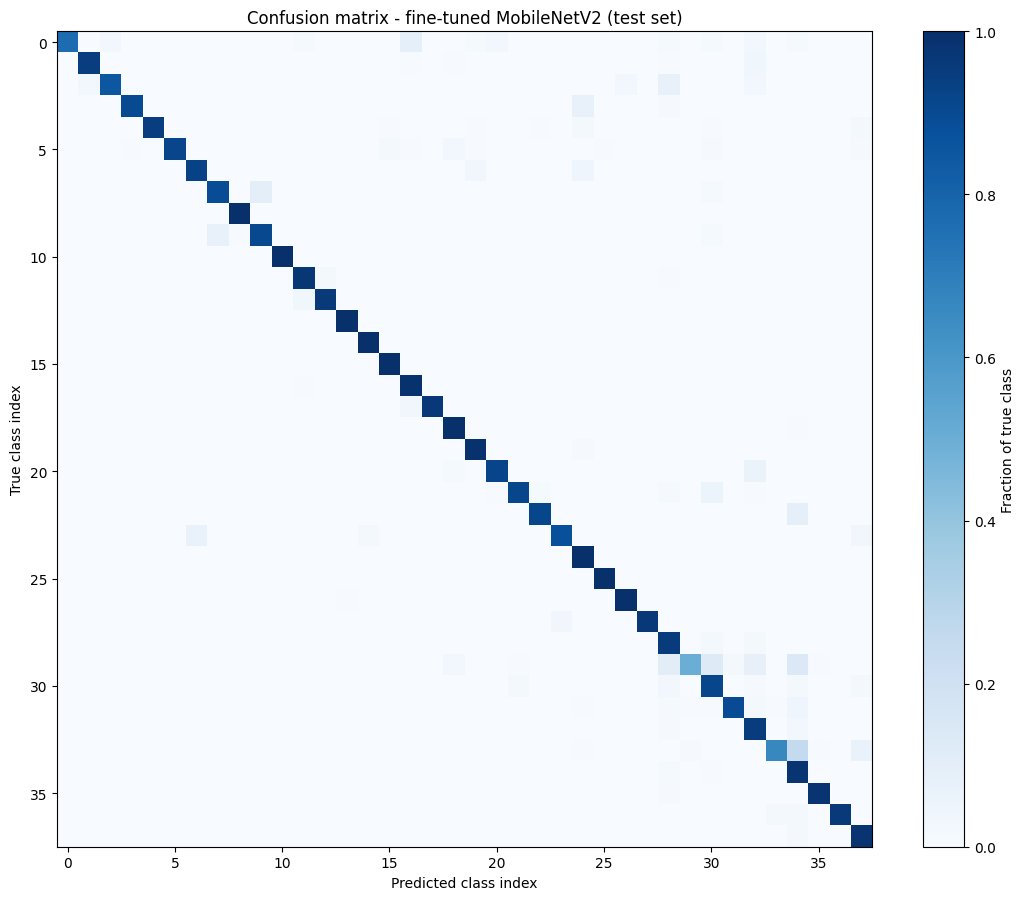


Top confused pairs (true -> predicted):
 64  Tomato___Spider_mites Two-spotted_spider_mite  ->  Tomato___Target_Spot
 25  Apple___healthy  ->  Soybean___healthy
 23  Tomato___Early_blight  ->  Tomato___Target_Spot
 20  Tomato___Early_blight  ->  Tomato___Late_blight
 17  Tomato___Early_blight  ->  Tomato___Bacterial_spot
 17  Tomato___Spider_mites Two-spotted_spider_mite  ->  Tomato___healthy
 13  Tomato___Early_blight  ->  Tomato___Septoria_leaf_spot
 11  Corn_(maize)___Northern_Leaf_Blight  ->  Corn_(maize)___Cercospora_leaf_spot Gray_leaf_spot
  9  Potato___Early_blight  ->  Tomato___Septoria_leaf_spot
  8  Corn_(maize)___Cercospora_leaf_spot Gray_leaf_spot  ->  Corn_(maize)___Northern_Leaf_Blight

Weakest classes (per-class accuracy):
0.500  Tomato___Early_blight  (164 test images)
0.663  Tomato___Spider_mites Two-spotted_spider_mite  (252 test images)
0.769  Apple___Apple_scab  (78 test images)
0.850  Apple___Cedar_apple_rust  (40 test images)
0.877  Raspberry___healthy  (57 test

In [ ]:
from sklearn.metrics import confusion_matrix
import matplotlib.pyplot as plt

# --- 1. Final test accuracy for all three models (test set used once, here) ---
model_files = {
    'Baseline CNN':           f'{PROJ}/models/baseline_best.keras',
    'MobileNetV2 (frozen)':   f'{PROJ}/models/mobilenet_frozen_best.keras',
    'MobileNetV2 (fine-tuned)': f'{PROJ}/models/mobilenet_finetuned_best.keras',
}
test_results = {}
for name, path in model_files.items():
    m = keras.models.load_model(path)
    loss, acc = m.evaluate(test_ds, verbose=0)
    test_results[name] = float(acc)
    print(f"{name}: test accuracy = {acc:.4f}")

results = json.load(open(results_path))
results['test_acc'] = test_results
json.dump(results, open(results_path, 'w'))

# --- 2. Confusion matrix for the best model (fine-tuned) ---
best = keras.models.load_model(model_files['MobileNetV2 (fine-tuned)'])
y_pred = np.argmax(best.predict(test_ds, verbose=0), axis=1)
y_true = y_test                      # test_ds is not shuffled, so order matches
n_cls = len(class_names)
cm = confusion_matrix(y_true, y_pred, labels=list(range(n_cls)))
cm_norm = cm / cm.sum(axis=1, keepdims=True)

plt.figure(figsize=(11, 9))
plt.imshow(cm_norm, cmap='Blues')
plt.colorbar(label='Fraction of true class')
plt.xlabel('Predicted class index'); plt.ylabel('True class index')
plt.title('Confusion matrix - fine-tuned MobileNetV2 (test set)')
plt.tight_layout()
plt.savefig(f'{PROJ}/logs/confusion_matrix.png', dpi=150)
plt.show()

# --- 3. Most-confused pairs and weakest classes ---
off = cm.copy(); np.fill_diagonal(off, 0)
print("\nTop confused pairs (true -> predicted):")
for flat in np.argsort(off.ravel())[::-1][:10]:
    t, p = np.unravel_index(flat, off.shape)
    if off[t, p] > 0:
        print(f"{off[t, p]:3d}  {class_names[t]}  ->  {class_names[p]}")

per_class = cm.diagonal() / cm.sum(axis=1)
print("\nWeakest classes (per-class accuracy):")
for i in np.argsort(per_class)[:8]:
    print(f"{per_class[i]:.3f}  {class_names[i]}  ({cm[i].sum()} test images)")

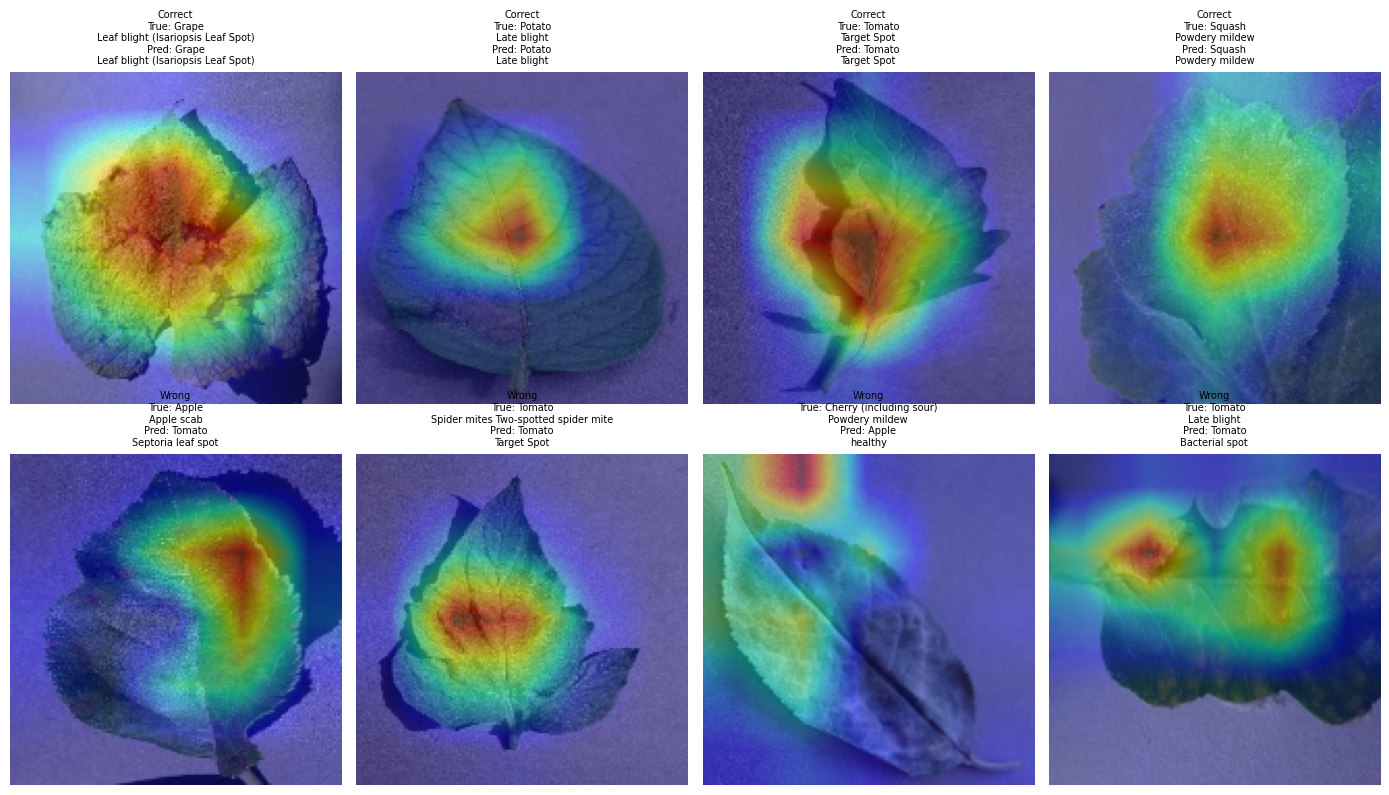

In [ ]:
# --- Grad-CAM: where is the fine-tuned model looking? ---
base = next(l for l in best.layers if isinstance(l, keras.Model))
idx = best.layers.index(base)
gap, dense = best.layers[idx + 1], best.layers[-1]

def load_img(path):
    img = tf.io.decode_image(tf.io.read_file(str(path)), channels=3, expand_animations=False)
    img.set_shape([None, None, 3])
    return tf.cast(tf.round(tf.image.resize(img, (IMG, IMG))), tf.uint8)

def gradcam(img_u8, class_idx=None):
    x = tf.cast(img_u8[None], tf.float32) / 127.5 - 1.0     # same scaling as the model
    with tf.GradientTape() as tape:
        conv = base(x, training=False)                       # last conv feature map
        probs = dense(gap(conv))
        if class_idx is None:
            class_idx = int(tf.argmax(probs[0]))
        score = probs[0, class_idx]
    grads = tape.gradient(score, conv)
    weights = tf.reduce_mean(grads, axis=(1, 2))             # importance of each channel
    cam = tf.reduce_sum(conv * weights[:, None, None, :], axis=-1)[0]
    cam = tf.nn.relu(cam)
    cam = cam / (tf.reduce_max(cam) + 1e-8)
    return cam.numpy(), class_idx

def short(n):
    crop, _, disease = n.partition('___')
    return f"{crop.replace('_', ' ')}\n{disease.replace('_', ' ')}"[:48]

rng = np.random.default_rng(0)
correct_idx = rng.choice(np.where(y_pred == y_true)[0], 4, replace=False)
wrong_idx = rng.choice(np.where(y_pred != y_true)[0], 4, replace=False)

fig, axes = plt.subplots(2, 4, figsize=(14, 8))
for row, (ids, tag) in enumerate([(correct_idx, 'Correct'), (wrong_idx, 'Wrong')]):
    for col, i in enumerate(ids):
        img = load_img(p_test[i])
        cam, pred_cls = gradcam(img)                          # heatmap for the PREDICTED class
        heat = tf.image.resize(cam[..., None], (IMG, IMG)).numpy()[..., 0]
        ax = axes[row, col]
        ax.imshow(img.numpy())
        ax.imshow(heat, cmap='jet', alpha=0.45)
        ax.set_title(f"{tag}\nTrue: {short(class_names[y_true[i]])}\nPred: {short(class_names[pred_cls])}",
                     fontsize=7)
        ax.axis('off')
plt.tight_layout()
plt.savefig(f'{PROJ}/logs/gradcam.png', dpi=150)
plt.show()

{
  "baseline_val_acc": 0.5655112266540527,
  "frozen_val_acc": 0.878488302230835,
  "finetuned_val_acc": 0.949317991733551,
  "test_acc": {
    "Baseline CNN": 0.5390511155128479,
    "MobileNetV2 (frozen)": 0.8616788387298584,
    "MobileNetV2 (fine-tuned)": 0.9454987645149231
  }
}


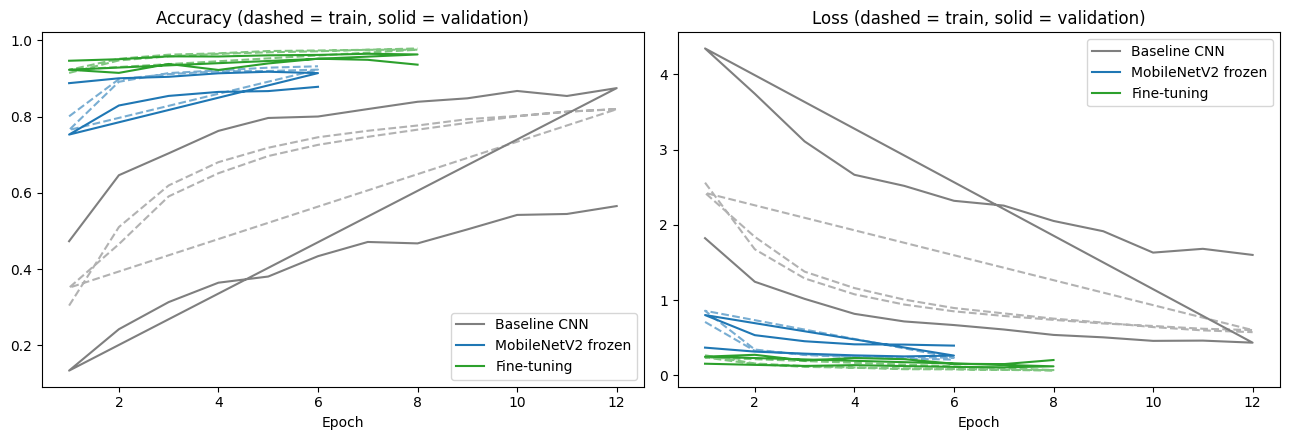

In [ ]:
import pandas as pd, json
import matplotlib.pyplot as plt

print(json.dumps(json.load(open(f'{PROJ}/logs/results.json')), indent=2))

stages = {
    'Baseline CNN':       pd.read_csv(f'{PROJ}/logs/baseline_log.csv'),
    'MobileNetV2 frozen': pd.read_csv(f'{PROJ}/logs/frozen_log.csv'),
    'Fine-tuning':        pd.read_csv(f'{PROJ}/logs/finetune_log.csv'),
}
fig, ax = plt.subplots(1, 2, figsize=(13, 4.5))
for (name, d), c in zip(stages.items(), ['tab:gray', 'tab:blue', 'tab:green']):
    ep = d['epoch'] + 1
    ax[0].plot(ep, d['accuracy'], '--', color=c, alpha=0.6)
    ax[0].plot(ep, d['val_accuracy'], '-', color=c, label=name)
    ax[1].plot(ep, d['loss'], '--', color=c, alpha=0.6)
    ax[1].plot(ep, d['val_loss'], '-', color=c, label=name)
ax[0].set_title('Accuracy (dashed = train, solid = validation)'); ax[0].set_xlabel('Epoch'); ax[0].legend()
ax[1].set_title('Loss (dashed = train, solid = validation)');     ax[1].set_xlabel('Epoch'); ax[1].legend()
plt.tight_layout()
plt.savefig(f'{PROJ}/logs/training_curves.png', dpi=150)
plt.show()